# Prise en main du simulateur

Ce carnet fait le tour du simulateur en quelques étapes : charger les paramètres, lancer une courte simulation, regarder les tables produites et retrouver les mécanismes décrits dans le guide SimPy (ressources, demandes de lit, hébergement).

Il se lance depuis la racine du dépôt (`jupyter lab notebooks/prise_en_main.ipynb`).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # pour importer gen_admissions depuis le dossier notebooks
import pandas as pd

from gen_admissions import config, controle, export, moteur

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

## 1. Les paramètres

Tout ce que le simulateur sait de l'hôpital vient du dossier `parametres/hopital_type`. La fonction `config.charger` lit les fichiers, vérifie leur cohérence (probabilités qui somment à 1, services qui existent…) et renvoie un objet `Parametres`.

In [2]:
p = config.charger("../parametres/hopital_type")
lits = pd.DataFrame([(s.code, s.libelle, s.lits, ", ".join(s.hebergement)) for s in p.services.values() if s.lits > 0],
                    columns=["service", "libellé", "lits", "hébergement possible dans"])
print(f"{lits['lits'].sum()} lits, {p.urgences['passages_par_an']} passages aux urgences par an")
lits

476 lits, 45000 passages aux urgences par an


,service,libellé,lits,hébergement possible dans
0,UHCD,Unité d'hospitalisation de courte durée,10,MED_POLY
1,REA,Réanimation,20,
2,USC,Soins continus,12,
3,USIC,Soins intensifs cardiologiques,8,
4,CARDIO,Cardiologie,36,"MED_INT, PNEUMO, MED_POLY"
5,PNEUMO,Pneumologie,30,"MED_INT, CARDIO, MED_POLY"
6,MED_INT,Médecine interne,40,"PNEUMO, MED_POLY, GASTRO"
7,GERIA,Gériatrie aiguë,40,"MED_INT, MED_POLY"
8,NEURO,Neurologie,30,"MED_INT, MED_POLY"
9,GASTRO,Gastro-entérologie,28,"MED_INT, CHIR_DIG"


Le catalogue de trajectoires donne les parcours complets les plus fréquents, avec leur effectif observé (fictif ici). Les séjours que le catalogue ne couvre pas sont construits étape par étape avec la table de passage.

In [3]:
p.catalogue.sort_values("effectif", ascending=False)[["trajectoire", "mode_entree", "classe_age", "sexe", "mode_sortie", "effectif"]].head(10)

,trajectoire,mode_entree,classe_age,sexe,mode_sortie,effectif
15,GYN_OBS,programme,18-64,F,domicile,7887
7,PED,programme,0-17,M,domicile,5905
0,PED,programme,0-17,F,domicile,5511
43,URO,programme,18-64,M,domicile,1562
44,GASTRO,programme,18-64,M,domicile,1322
16,GASTRO,programme,18-64,F,domicile,1281
98,URO,programme,65-79,M,domicile,1277
300,UHCD,urgences,80+,F,domicile,1014
17,ONCO,programme,18-64,F,domicile,1005
45,CHIR_DIG,programme,18-64,M,domicile,1002


## 2. Lancer une simulation

`moteur.simuler` crée l'hôpital virtuel (un environnement SimPy, une ressource de lits par service, les générateurs de patients) et fait tourner l'horloge. On simule ici 60 jours, après 14 jours de chauffe (le temps que l'hôpital, vide au départ, se remplisse).

In [4]:
r = moteur.simuler(p, graine=42, duree_jours=60, chauffe_jours=14, marge_fin_jours=30)
print(f"{len(r.passages)} passages aux urgences et {len(r.sejours)} séjours simulés (chauffe et marge comprises)")

13379 passages aux urgences et 8185 séjours simulés (chauffe et marge comprises)


## 3. Les tables produites

`export.tables` transforme le journal de la simulation en tables au format proche des formats réels. Seuls les passages et séjours commencés pendant la période de collecte (après la chauffe) sont conservés.

In [5]:
t = export.tables(r)
{nom: len(df) for nom, df in t.items()}

{'rpu': 7704,
 'rss': 4655,
 'rum': 6076,
 'mouvements': 10724,
 'verite_sejours': 4655,
 'verite_passages': 7704,
 'patients': 16045}

In [6]:
t["rpu"].head()

,id_passage,id_patient,date_entree,date_sortie,age,sexe,gravite_ccmu,mode_sortie,destination,duree_passage_h,id_sejour
0,U0001884,P002300,2026-01-15 00:14,2026-01-15 08:18,66,M,3,domicile,,8.07,
1,U0001885,P002301,2026-01-15 00:48,2026-01-15 01:28,2,M,3,domicile,,0.67,
2,U0001886,P002302,2026-01-15 00:59,2026-01-15 02:55,46,F,3,domicile,,1.93,
3,U0001887,P002303,2026-01-15 01:25,2026-01-15 04:01,58,M,2,domicile,,2.60,
4,U0001888,P002304,2026-01-15 01:34,2026-01-15 04:50,37,F,2,domicile,,3.27,


In [7]:
t["rum"].head(8)

,id_sejour,id_patient,rang,unite,date_entree,date_sortie,mode_entree,provenance,mode_sortie,destination,heberge,specialite_prevue,lit,duree_h
0,S001137,P002228,1,MED_POLY,2026-01-15,2026-01-16,8,,6,,oui,NEURO,MED-05,33.43
1,S001137,P002228,2,NEURO,2026-01-16,2026-01-19,6,,6,,non,NEURO,NEU-15,60.73
2,S001137,P002228,3,REA,2026-01-19,2026-01-28,6,,6,,non,REA,REA-18,223.38
3,S001137,P002228,4,NEURO,2026-01-28,2026-02-09,6,,8,,non,NEURO,NEU-21,291.30
4,S001140,P001737,1,GYN_OBS,2026-01-15,2026-01-16,8,,8,,non,GYN_OBS,GYN-30,35.64
5,S001151,P002250,1,GYN_OBS,2026-01-15,2026-01-17,8,,8,,non,GYN_OBS,GYN-08,49.44
6,S001157,P002265,1,MED_INT,2026-01-15,2026-01-16,8,,8,,oui,NEURO,MED-38,34.43
7,S001165,P002276,1,GYN_OBS,2026-01-15,2026-01-19,8,,8,,non,GYN_OBS,GYN-32,99.38


### Suivre un patient hébergé

Dans la vérité de référence, on retrouve exactement ce qui a été simulé : trajectoire prévue, trajectoire réalisée, hébergements. Cherchons un séjour avec un hébergement suivi d'un retour dans le service prévu, et regardons ses RUM et ses mouvements.

In [8]:
v = t["verite_sejours"]
exemple = v[(v["nb_retours_origine"] > 0) & (v["nb_rum"] >= 3)].iloc[0]
exemple

id_sejour                                      S001137
mode_entree                                  programme
origine_parcours                                 table
trajectoire_prevue                               NEURO
trajectoire_realisee    MED_POLY > NEURO > REA > NEURO
nb_rum                                               4
nb_hebergements                                      1
nb_retours_origine                                   1
attente_entree_h                                  12.0
attente_mutations_h                                0.0
termine                                           True
Name: 0, dtype: object

In [9]:
t["rum"][t["rum"]["id_sejour"] == exemple["id_sejour"]]

,id_sejour,id_patient,rang,unite,date_entree,date_sortie,mode_entree,provenance,mode_sortie,destination,heberge,specialite_prevue,lit,duree_h
0,S001137,P002228,1,MED_POLY,2026-01-15,2026-01-16,8,,6,,oui,NEURO,MED-05,33.43
1,S001137,P002228,2,NEURO,2026-01-16,2026-01-19,6,,6,,non,NEURO,NEU-15,60.73
2,S001137,P002228,3,REA,2026-01-19,2026-01-28,6,,6,,non,REA,REA-18,223.38
3,S001137,P002228,4,NEURO,2026-01-28,2026-02-09,6,,8,,non,NEURO,NEU-21,291.30


In [10]:
t["mouvements"][t["mouvements"]["id_sejour"] == exemple["id_sejour"]]

,id_sejour,id_patient,date_heure,type,unite_depart,lit_depart,unite_arrivee,lit_arrivee
0,S001137,P002228,2026-01-15 03:26,entree,,,MED_POLY,MED-05
143,S001137,P002228,2026-01-16 12:52,mutation,MED_POLY,MED-05,NEURO,NEU-15
308,S001137,P002228,2026-01-19 01:36,mutation,NEURO,NEU-15,REA,REA-18
1899,S001137,P002228,2026-01-28 08:58,mutation,REA,REA-18,NEURO,NEU-21
4128,S001137,P002228,2026-02-09 12:16,sortie,NEURO,NEU-21,,


On lit : le patient relève de la spécialité prévue, mais entre d'abord dans un autre service (`heberge = oui`), puis une mutation (mode de sortie 6, mode d'entrée 6) le ramène dans son service dès qu'un lit s'y libère. C'est le mécanisme de `lits.py` : la demande de lit dans le service prévu reste en attente pendant l'hébergement.

## 4. Le tableau de contrôle

`controle.indicateurs` calcule les indicateurs de la section 7.1 du plan et les compare aux cibles du fichier `cibles.csv`. Sur une période courte, les indicateurs sont plus bruités que sur un an.

In [11]:
ind = controle.indicateurs(r, t)
ind[ind["indicateur"] != "dms_j"]

,indicateur,service,valeur,valeur_min,valeur_max,statut
0,taux_occupation,UHCD,0.7590,0.689,0.869,OK
1,taux_occupation,REA,0.8370,0.723,0.873,OK
2,taux_occupation,USC,0.7660,0.661,0.831,OK
3,taux_occupation,USIC,0.6310,0.629,0.824,OK
4,taux_occupation,CARDIO,0.9400,0.878,1.000,OK
5,taux_occupation,PNEUMO,0.9050,0.850,0.990,OK
6,taux_occupation,MED_INT,0.9170,0.850,0.985,OK
7,taux_occupation,GERIA,0.9260,0.848,0.983,OK
8,taux_occupation,NEURO,0.8240,0.803,0.943,OK
9,taux_occupation,GASTRO,0.8450,0.787,0.928,OK


L'occupation journalière montre les services qui saturent et les creux du week-end. En pointillés, la capacité.

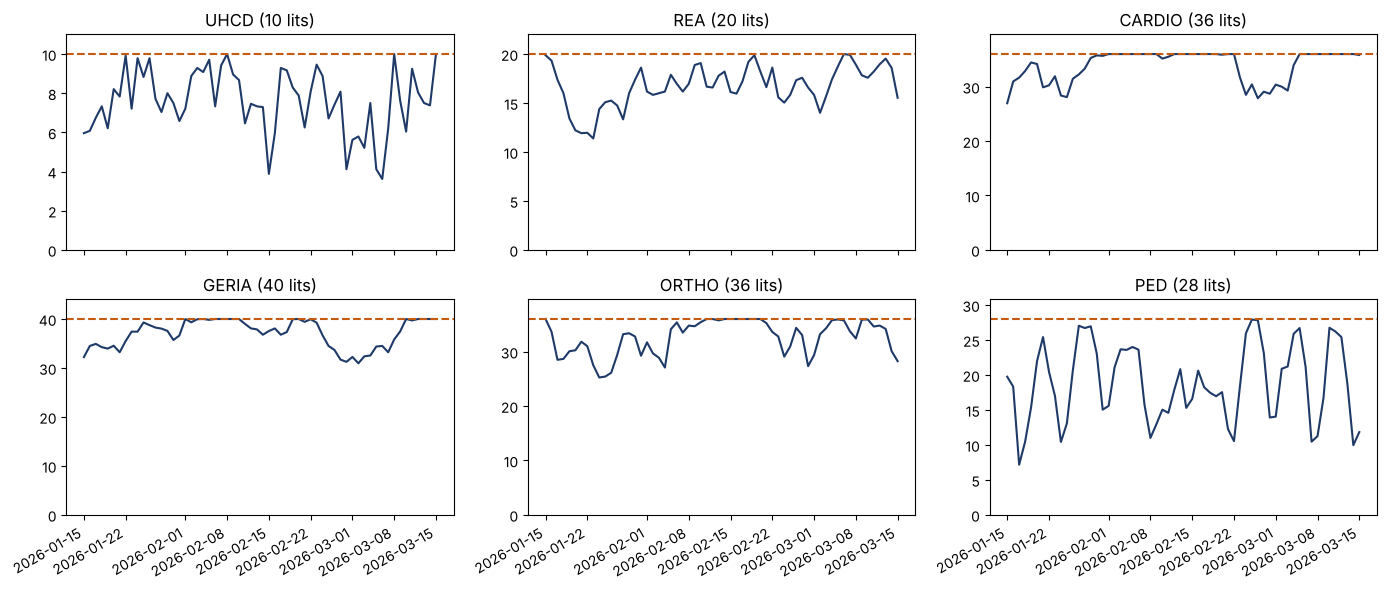

In [12]:
import matplotlib.pyplot as plt

occ = controle.occupation_journaliere(r)
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, s in zip(axes.flat, ["UHCD", "REA", "CARDIO", "GERIA", "ORTHO", "PED"]):
    ax.plot(pd.to_datetime(occ["date"]), occ[s], color="#1F3A68")
    ax.axhline(p.services[s].lits, ls="--", color="#C55A11")
    ax.set_title(f"{s} ({p.services[s].lits} lits)")
    ax.set_ylim(0, p.services[s].lits * 1.1)
fig.autofmt_xdate(); fig.tight_layout()

## 5. Pour aller plus loin

- `python -m gen_admissions simuler parametres/hopital_type sorties/essai --graine 42` simule un an et écrit tout (CSV, Parquet, contrôle, graphique).
- Changer un nombre de lits dans `structure.yaml`, ou une règle d'attente, et relancer : les attentes et hébergements changent.
- `scripts/fabriquer_parametres.py` montre comment les paramètres sont extraits d'un tableau de passages d'unités ; la même fonction servira pour les données réelles.